# 实验六 B · Stable Diffusion 的六色版画 LoRA
用 48 张风格化照片训练 U-Net 注意力层中的 LoRA。以相同提示词、随机种子、分辨率与采样设置生成两组图，观察模型能否将目标风格迁移到不同主体。

In [1]:
from pathlib import Path
import sys, gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision.transforms.functional import to_tensor
from PIL import Image
from diffusers import StableDiffusionPipeline, DDPMScheduler, DDIMScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from peft import LoraConfig, get_peft_model_state_dict
root = Path('exp6' if Path('exp6/data_index.csv').exists() else '.').resolve()
sys.path.insert(0,str(root))
from style_data import photo, poster, PALETTE
out = root/'results'/'exp6B'; out.mkdir(parents=True,exist_ok=True)
cache = root.parent/'.cache'/'exp6'; cache.mkdir(parents=True,exist_ok=True)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
dtype = torch.float16 if device=='cuda' else torch.float32
torch.manual_seed(6026); torch.set_num_threads(4)
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei','SimHei','DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

## 收集、筛选和 Caption
从实验四 COCO-CN 训练清单按固定随机顺序选取短边至少 256 像素且文件哈希各异的照片，依据原始中文描述匹配 8 种主体，每种 6 张。中心裁剪到 320×320，应用与 A 相同的六色映射。英文 Caption 使用固定风格词 tideprint 和主体名，例如 `a tideprint illustration of a giraffe`。原始描述保存在数据清单，自动匹配可能遗漏场景细节。

caption
a tideprint illustration of a giraffe       6
a tideprint illustration of a zebra         6
a tideprint illustration of a cat           6
a tideprint illustration of a motorcycle    6
a tideprint illustration of a train         6
a tideprint illustration of an elephant     6
a tideprint illustration of an airplane     6
a tideprint illustration of a bus           6
Name: count, dtype: int64


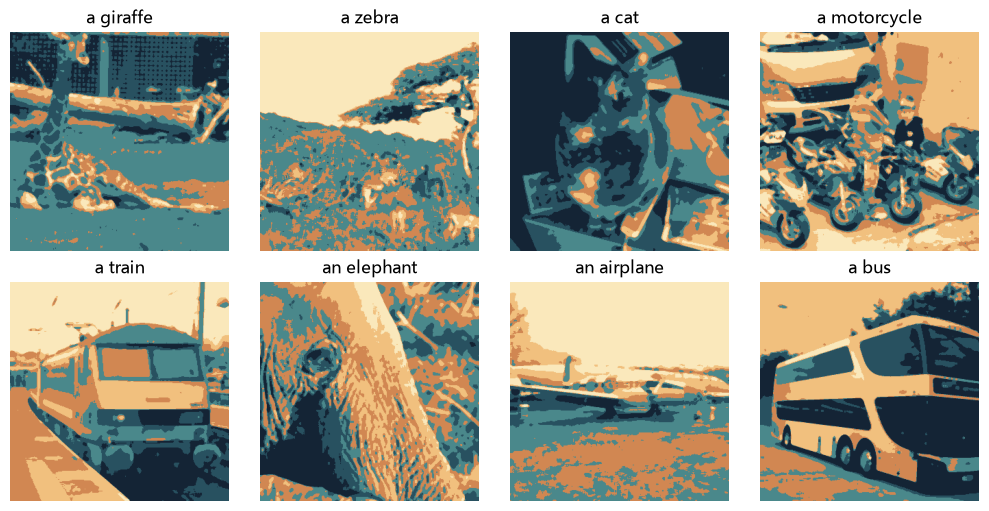

In [2]:
index = pd.read_csv(root/'data_index.csv').dropna(subset=['caption']).reset_index(drop=True)
images = [poster(photo(row,root,320)) for row in index.itertuples()]
print(index.caption.value_counts())
examples = index.drop_duplicates('caption').index
fig,axes = plt.subplots(2,4,figsize=(10,5),layout='constrained')
for ax,i in zip(axes.flat,examples):
    ax.imshow(images[i]); ax.set_title(index.caption[i].split(' of ')[1]); ax.axis('off')
fig.savefig(out/'training_examples.png',dpi=150); plt.show()

## 预训练模型与生成原理
[Stable Diffusion v1.5 模型卡](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)。VAE 将训练图像压缩成潜变量。CLIP 文本编码器把提示词转成嵌入，U-Net 接收带噪潜变量、时间步和文本嵌入，学习预测噪声。生成时从随机噪声开始，调度器根据模型预测逐步去噪，最后用 VAE 解码成 RGB 图像。

In [3]:
model_id = 'stable-diffusion-v1-5/stable-diffusion-v1-5'
rev = '451f4fe16113bff5a5d2269ed5ad43b0592e9a14'
local = cache/'sd15'
parts = ['unet/diffusion_pytorch_model.fp16.safetensors','text_encoder/model.fp16.safetensors',
         'vae/diffusion_pytorch_model.fp16.safetensors','safety_checker/model.fp16.safetensors']
source = str(local) if all((local/p).is_file() for p in parts) else model_id
pipe = StableDiffusionPipeline.from_pretrained(source,revision=rev if source==model_id else None,
            variant='fp16',torch_dtype=dtype,use_safetensors=True,cache_dir=cache/'hub').to(device)
pipe.set_progress_bar_config(disable=True)
noise_scheduler = DDPMScheduler.from_config(pipe.scheduler.config)
assert noise_scheduler.config.prediction_type == 'epsilon'
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
for part in (pipe.vae,pipe.text_encoder,pipe.unet): part.requires_grad_(False).eval()

E:\CODE\Tutorial\DeepLearning-exp\.cache\exp5-env\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

## 微调前基线
测试已见主体的新场景，以及训练集八种主体之外的灯塔。每个提示词在微调前后使用相同初始噪声。保存全部配对图像。

In [4]:
prompts = ['a tideprint illustration of a cat on a windowsill',
           'a tideprint illustration of a train crossing a bridge',
           'a tideprint illustration of a lighthouse beside the sea']
seeds = [601,602,603]
def generate(stage):
    results = []
    for i,(prompt,seed) in enumerate(zip(prompts,seeds)):
        result = pipe(prompt,generator=torch.Generator(device='cpu').manual_seed(seed),height=384,width=384,
                      num_inference_steps=25,guidance_scale=7.5)
        result.images[0].save(out/f'{stage}_{i+1}.png'); results.append(result.images[0])
        print(stage,i+1,'过滤标记',result.nsfw_content_detected)
    return results
before = generate('before')

before 1 过滤标记 [False]


before 2 过滤标记 [False]


before 3 过滤标记 [False]


## 低秩适配与噪声预测训练
固定预训练权重 W，将注意力投影替换为 W + (α/r)BA。A 和 B 构成秩不超过 r 的更新。本实验取 r=4、α=4，在 U-Net 的 Q、K、V 和输出投影中训练这些矩阵。全量微调需要更新原权重并保存对应优化器状态。本实验只为新增矩阵计算参数更新。

In [5]:
# 预编码图像和文本，将 VAE、CLIP 和过滤器暂移至内存以节约训练显存。
with torch.no_grad():
    latents = torch.cat([pipe.vae.encode((to_tensor(im)[None]*2-1).to(device,dtype)).latent_dist.sample().cpu()
                         for im in images]) * pipe.vae.config.scaling_factor
    tokens = pipe.tokenizer(index.caption.tolist(),padding='max_length',truncation=True,
                            max_length=pipe.tokenizer.model_max_length,return_tensors='pt')
    embeds = pipe.text_encoder(tokens.input_ids.to(device))[0].cpu()
for part in (pipe.vae,pipe.text_encoder,pipe.safety_checker): part.to('cpu')
gc.collect(); torch.cuda.empty_cache()
unet = pipe.unet
config = LoraConfig(r=4,lora_alpha=4,init_lora_weights='gaussian',target_modules=['to_q','to_k','to_v','to_out.0'])
unet.add_adapter(config); unet.train(); unet.enable_gradient_checkpointing()
params = [p for p in unet.parameters() if p.requires_grad]
for p in params: p.data = p.data.float()
num = sum(p.numel() for p in params); total = sum(p.numel() for p in unet.parameters())
print(f'LoRA 可训练参数 {num:,}，占适配后 U-Net 的 {100*num/total:.3f}%')
opt = torch.optim.AdamW(params,lr=2e-4)
scaler = torch.amp.GradScaler('cuda',enabled=device=='cuda')
steps = 144; history = []; order = []
for step in range(1,steps+1):
    if not order: order = torch.randperm(len(index)).tolist()
    i = order.pop(); clean = latents[i:i+1].to(device,dtype)
    noise = torch.randn_like(clean); t = torch.randint(noise_scheduler.config.num_train_timesteps,(1,),device=device)
    noisy = noise_scheduler.add_noise(clean,noise,t)
    opt.zero_grad(set_to_none=True)
    with torch.autocast(device_type=device,dtype=dtype,enabled=device=='cuda'):
        pred = unet(noisy,t,encoder_hidden_states=embeds[i:i+1].to(device,dtype)).sample
        loss = torch.nn.functional.mse_loss(pred.float(),noise.float())
    scaler.scale(loss).backward(); scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(params,1.0); scaler.step(opt); scaler.update()
    history.append((step,i,t.item(),loss.item()))
unet.eval(); unet.disable_gradient_checkpointing()
log = pd.DataFrame(history,columns=['step','image_index','timestep','noise_mse']); log.to_csv(out/'training_loss.csv',index=False)
adapter_path = cache/'tideprint_lora'
pipe.save_lora_weights(save_directory=adapter_path,unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)))
print('权重保存到',adapter_path)

LoRA 可训练参数 797,184，占适配后 U-Net 的 0.093%


权重保存到 E:\CODE\Tutorial\DeepLearning-exp\.cache\exp6\tideprint_lora


## 固定 Prompt 对照与指标
计算每张生成图到目标六色调色板的平均最近色距离。结合生成图观察主体、构图和色块边界。三组图各使用一个随机种子，只支持本次样例分析。

after 1 过滤标记 [False]


after 2 过滤标记 [False]


after 3 过滤标记 [False]


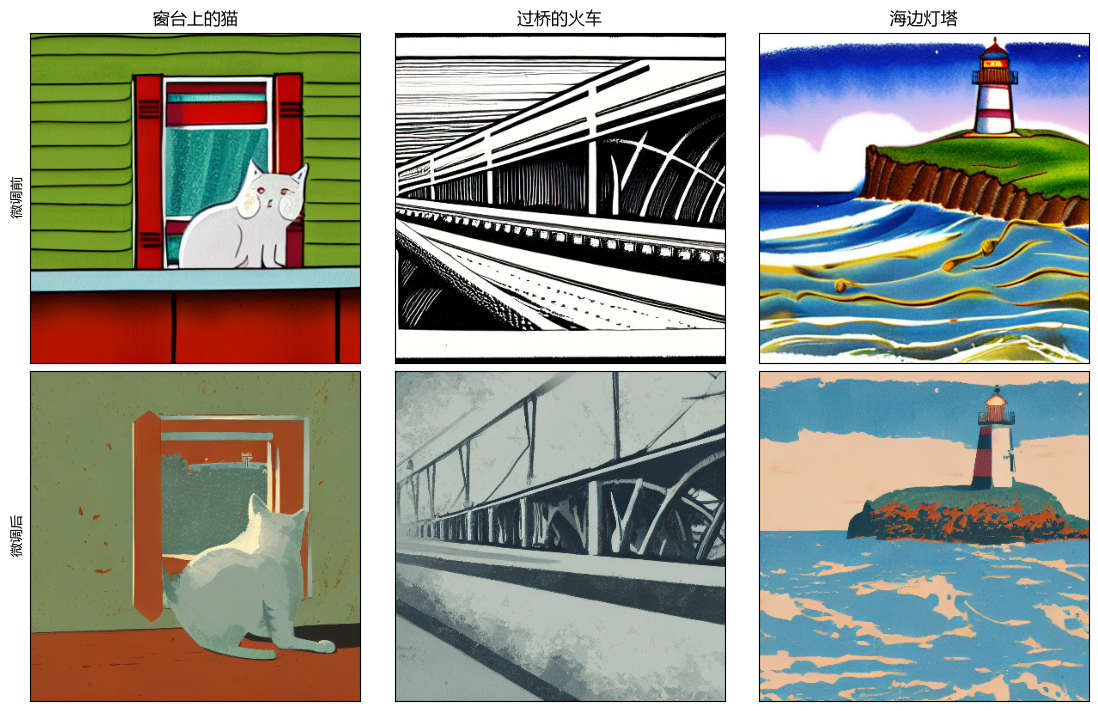

,stage,prompt,seed,palette_distance
0,before,a tideprint illustration of a cat on a windowsill,601,0.381397
1,after,a tideprint illustration of a cat on a windowsill,601,0.291712
2,before,a tideprint illustration of a train crossing a...,602,0.246861
3,after,a tideprint illustration of a train crossing a...,602,0.243041
4,before,a tideprint illustration of a lighthouse besid...,603,0.276016
5,after,a tideprint illustration of a lighthouse besid...,603,0.167607


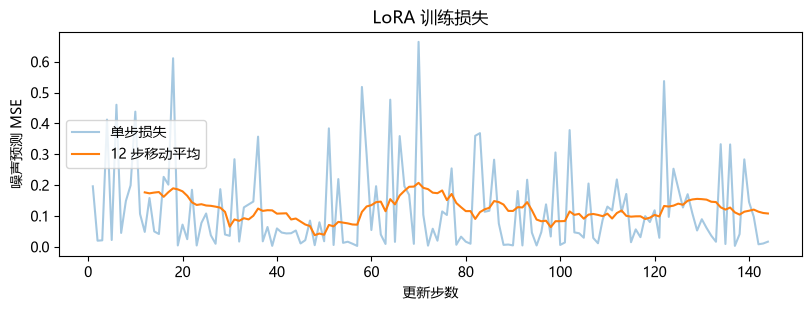

350

In [6]:
del opt; gc.collect(); torch.cuda.empty_cache()
pipe.to(device); after = generate('after')
fig,axes = plt.subplots(2,3,figsize=(11,7),layout='constrained'); records=[]
for j,(prompt,seed) in enumerate(zip(prompts,seeds)):
    for k,(stage,img) in enumerate([('before',before[j]),('after',after[j])]):
        ax = axes[k,j]; ax.imshow(img); ax.set(xticks=[],yticks=[])
        if k==0: ax.set_title(['窗台上的猫','过桥的火车','海边灯塔'][j])
        if j==0: ax.set_ylabel(['微调前','微调后'][k])
        arr = np.asarray(img,dtype=np.float32)/255
        dist = np.linalg.norm(arr[:,:,None,:]-PALETTE/255,axis=-1).min(axis=-1).mean()
        records.append([stage,prompt,seed,dist])
fig.savefig(out/'prompt_comparison.png',dpi=150); plt.show()
metrics = pd.DataFrame(records,columns=['stage','prompt','seed','palette_distance']); metrics.to_csv(out/'prompt_metrics.csv',index=False); display(metrics)
fig,ax = plt.subplots(figsize=(8,3),layout='constrained'); ax.plot(log.step,log.noise_mse,alpha=0.4,label='单步损失')
ax.plot(log.step,log.noise_mse.rolling(12).mean(),label='12 步移动平均'); ax.legend(); ax.set(xlabel='更新步数',ylabel='噪声预测 MSE',title='LoRA 训练损失')
fig.savefig(out/'loss.png',dpi=150); plt.show()
(out/'settings.json').write_text(json.dumps(dict(model=model_id,revision=rev,trainable=num,unet_total=total,rank=4,alpha=4,
        seed=6026,steps=steps,batch_size=1,lr=2e-4,training_size=320,inference_size=384,ddim_steps=25,guidance=7.5),indent=2))